## Claim Verification Results on the Development partition of the gold-retrieved evidence

In [1]:
MODEL_NAME_MAPPING = {
    'ms-marco-MiniLM-L12-v2': "MS-MARCO-MiniLM",
    'ms-marco-MiniLM-L-12-v2': "MS-MARCO-MiniLM",
    'BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext': 'BioMedBERT',
    'gemini-2.5-pro-preview-03-25': "Gemini 2.5",
    'gpt-4.1': 'GPT 4.1',
    'bert-large-uncased': 'BERT',
    'MedCPT-Cross-Encoder': 'MedCPT',
    'specter2_base': 'Specter2',
    'specter': 'Specter',
    'tfidf': 'TF-IDF',
    'bge-reranker-large': 'BGE',
    'Meta-Llama-3.1-8B-Instruct': 'Llama 3.1 [8B]',
    'Meta-Llama-3.1-70B-Instruct': 'Llama 3.1',
    'Mixtral-8x7B-Instruct-v0.1': 'Mixtral',
    'multilingual-e5-large-instruct': 'Multilingual E5',
    'bm25-lucene': 'BM25',
    'reranker-ModernBERT-large-gooaq-bce': 'ModernBERT',
    'Qwen3-Reranker-4B': 'Qwen3 4B',
    'Qwen3-Reranker-0.6B': 'Qwen3 0.6B',
    'Qwen3-Reranker-8B': 'Qwen3 8B',
    'gpt-5.2': 'GPT 5.2',
    'Llama-4-Scout-17B-16E-Instruct': 'Llama 4',
    'Llama-3.2-1B-Instruct': 'Llama 3.2 [1B]',
    'Llama-3.2-3B-Instruct': 'Llama 3.2',
    'Qwen3.5-9B': 'Qwen3.5 [9B]',
    'gemma-4-31B-it': 'Gemma 4'
}

PARTITION = 'dev'
VERSION = '2026.03.03'
DATASET = 'civicfact'

In [2]:
import seaborn as sns

from utils import add_bar_labels, read_jsonl

def ci_95(series):
    return (series.quantile(0.025), series.quantile(0.975))

ERR_KWS={'linewidth': 1, 'color': '#00000099'}


def create_and_filter_model_names(df):
    df["model"] = df['filepath.model_dir'].str.split("__").str[-1].apply(lambda x: MODEL_NAME_MAPPING.get(x, x))
    df.loc[~df['filepath.train_data_version'].isna(), 'model'] += ' (FT)'
    df.loc[df['filepath.train_dataset'] == 'civicfactx5000g8', 'model'] += ' expl-1'
    df.loc[df['filepath.train_dataset'] == 'civicfactxf1.0g8', 'model'] += ' expl'
    df.loc[df['filepath.train_dataset'] == 'civicfactchunk', 'model'] += ' expl/chunks'
    df = df[~df.model.isin({'Llama 3.2 [1B]', 'Llama 3.2 [1B]', 'Llama 3.2 [1B] (FT)',  'Llama 3.2 [1B] (FT)', 'Llama 3.1 [8B]', 'Llama 3.1 [8B] (FT)'})]
    df.loc[df.model.str.contains('(FT)', regex=False), 'model'] += ' c' + df['filepath.config']
    return df


## What about at the level of the revision?

In [3]:
claims_df = read_jsonl(f'../data/civicfact-{VERSION}/data.jsonl.gz')
print(claims_df['pmid.partition'].value_counts(dropna=False))
claims_df = claims_df[claims_df['pmid.partition'].isin({'dev', 'test'})]
claims_df = claims_df[claims_df.gold_label_name == 'SUPPORTS']
claims_df = claims_df[['document.pmid', 'claim.flat']].drop_duplicates().rename(columns={'claim.flat': 'revised_claim.flat'})
claims_df.head()

pmid.partition
train    10205
dev       1167
test      1076
Name: count, dtype: int64


,document.pmid,revised_claim.flat
1,23995526,"{\n ""disease"": ""Renal Cell Carcinoma"",\n ""ev..."
14,22274685,"{\n ""disease"": ""Epithelial Ovarian Cancer"",\n..."
20,22274685,"{\n ""disease"": ""Epithelial Ovarian Cancer"",\n..."
29,16076867,"{\n ""disease"": ""Acute Myeloid Leukemia"",\n ""..."
35,26162296,"{\n ""disease"": ""Bladder Carcinoma"",\n ""evide..."


In [4]:
# now how accurate are they on the actual revision suggested?
import glob
import os

files = [
    '../results/claim_verification/api/evaluations/openai__gpt-5.2/civicfact-2026.03.03/chat-default/gen-11/prompts.jsonexampleslimit200.30-shot.*.processed.jsonl.gz',
    '../results/claim_verification/evaluations/google__gemma-4-31B-it/civicfact-2026.03.03/chat-default/gen-16/prompts.jsonexampleslimit200.15-shot.*.processed.jsonl.gz',
    # '../results/claim_verification/evaluations/meta-llama__Llama-3.2-3B-Instruct/civicfactxf1.0g8-2026.03.03/chat-default/gen-12/prompts.jsonexampleslimit200.3-shot.*.processed.jsonl.gz',
    '../results/claim_verification/fine-tuning/config-16/completion/civicfactchunk-2026.03.03/chat-default/prompts.verifyevidencetrain.0-shot.train.jsonl/meta-llama__Llama-3.2-3B-Instruct/evaluations/civicfact-2026.03.03/chat-default/gen-5/prompts.verifyevidencetrain.0-shot.*.processed.jsonl.gz'

]
# pairs-head-oracle-L5000-qt0
retrieval_types = ['qwen-mongoose']

target_files = set(files)
for file in files:
    for ret_type in retrieval_types:
        target_files.update(glob.glob(file.replace('/civicfact-2026.03.03/', f'/civicfactpairs-{ret_type}-L5000-qt0-2026.03.03/')))
        target_files.update(glob.glob(file.replace('/civicfactxf1.0g8-2026.03.03/', f'/civicfactxf1.0g8pairs-{ret_type}-L5000-qt0-2026.03.03/')))

print(len(target_files))
target_files = [f for f in target_files if os.path.exists(f)]
print(len(target_files))
rev_df = read_jsonl(*target_files, add_filename=True, add_filepath_metadata=True)

rev_df['retrieval'] = rev_df['filepath.ret_model'].fillna('Human')
rev_df.loc[rev_df['filepath.ret_model'] == 'head-oracle', 'retrieval'] = 'Oracle'

rev_df = create_and_filter_model_names(rev_df)
rev_df = rev_df[(rev_df.gold_label_name == 'REVISIONS')]
print(rev_df.model.unique())

print(rev_df.columns.tolist())
rev_df.head()

15
12
<ArrowStringArray>
['Gemma 4', 'Llama 3.2 (FT) expl/chunks c16', 'GPT 5.2']
Length: 3, dtype: str
['assignment.round', 'balance_args.maximization_factor', 'balance_args.ngram', 'chat', 'chat_template', 'civic.claim', 'civic.claim.flat', 'civic.corrections', 'civic.events', 'civic.evidenceDirection', 'civic.evidenceLevel', 'civic.evidenceRating', 'civic.evidenceType', 'civic.flagged', 'civic.ground_truth', 'civic.id', 'civic.lastUpdatedAt', 'civic.revision_note', 'civic.revision_state', 'civic.status', 'claim', 'claim.flat', 'claim.generated', 'claim.id', 'claim.source', 'conversation', 'description.scores', 'description.status', 'display_id', 'document.doi', 'document.license', 'document.pmcid', 'document.pmid', 'document.title', 'evidence', 'evidence.flat', 'evidence.generated', 'evidence.id', 'evidence.selection_method', 'evidence.source', 'example', 'example.id', 'examples', 'expected_response', 'expected_response.tokens', 'flagged', 'generated', 'generated_text', 'gold_label_

,assignment.round,balance_args.maximization_factor,balance_args.ngram,chat,chat_template,civic.claim,civic.claim.flat,civic.corrections,civic.events,civic.evidenceDirection,...,last_updated,prompt,request,request.api,request.max_completion_tokens,request.model,request.reasoning_effort,request.temperature,response,retrieval
35,1,3.0,2,[{'content': '# Instructions You will be give...,default,{'content': {'disease': 'Von Hippel-Lindau Dis...,"{\n ""disease"": ""Von Hippel-Lindau Disease"",\n...",NaN,"[{'action': 'REVISION_ACCEPTED', 'createdAt': ...",SUPPORTS,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Human
37,1,3.0,2,[{'content': '# Instructions You will be give...,default,{'content': {'disease': 'Von Hippel-Lindau Dis...,"{\n ""disease"": ""Von Hippel-Lindau Disease"",\n...",NaN,"[{'action': 'REVISION_ACCEPTED', 'createdAt': ...",SUPPORTS,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Human
39,1,3.0,2,[{'content': '# Instructions You will be give...,default,"{'content': {'evidenceDirection': 'SUPPORTS', ...","{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",NaN,"[{'action': 'ACCEPTED', 'createdAt': '2023-03-...",SUPPORTS,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Human
40,1,3.0,2,[{'content': '# Instructions You will be give...,default,{'content': {'disease': 'Pancreatic Ductal Car...,"{\n ""disease"": ""Pancreatic Ductal Carcinoma"",...",NaN,"[{'action': 'REVISION_SUGGESTED', 'createdAt':...",SUPPORTS,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Human
41,1,3.0,2,[{'content': '# Instructions You will be give...,default,{'content': {'disease': 'Pancreatic Ductal Car...,"{\n ""disease"": ""Pancreatic Ductal Carcinoma"",...",NaN,"[{'action': 'REVISION_SUGGESTED', 'createdAt':...",SUPPORTS,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Human


In [5]:
import re

def extract_predicted_revision(text):
    text = text.strip()

    m = re.search(r'^(?P<label>SUPPORTS|NEI)\n+(?P<explanation>.*)', text, flags=re.MULTILINE | re.IGNORECASE)
    if m:
        return m.groupdict()
    m = re.search(r'^(?P<label>NEI|SUPPORTS)\b', text, flags=re.MULTILINE | re.IGNORECASE)
    if m:
        return m.groupdict()
    m = re.search(r'^label: (?P<label>SUPPORTS|NEI)\n+revised claim: none(\n+(explanation: )?(?P<explanation>.*))?', text, flags=re.MULTILINE | re.IGNORECASE)
    if m:
        return m.groupdict()
    m = re.search(r'^label: (?P<label>REVISIONS)\n+revised claim:\n(```json\n)?(?P<revision>\{(.|\n)+\})(```)?\n+(explanation: )?(?P<explanation>.*)', text, flags=re.MULTILINE | re.IGNORECASE)
    if m:
        return m.groupdict()
    m = re.search(r'^(?P<label>REVISIONS)\n+(```json\n)?(?P<revision>\{(.|\n)+\})(```)?\n+(?P<explanation>.*)', text, flags=re.MULTILINE | re.IGNORECASE)
    if m:
        return m.groupdict()
    return None


rev_df['parsed'] = rev_df.generated_text.map(extract_predicted_revision)
rev_df['parse_ok'] = ~rev_df.parsed.isna()

print(rev_df[['model', 'filepath.partition', 'parse_ok']].value_counts(dropna=False))

model                           filepath.partition  parse_ok
GPT 5.2                         dev                 True        677
Llama 3.2 (FT) expl/chunks c16  dev                 True        677
Gemma 4                         dev                 True        677
Llama 3.2 (FT) expl/chunks c16  test                True        661
GPT 5.2                         test                True        661
Gemma 4                         test                True        659
                                                    False         2
Name: count, dtype: int64


In [6]:
for _, row in rev_df[rev_df.parse_ok == False].iterrows():
    print(row['generated_text'])
    print('\n\n\n')

<|channel>thought
<channel|>REVISIONS

{
  "disease": "Melanoma",
  "evidenceDirection": "SUPPORTS",
  "evidenceType": "PREDICTIVE",
  "molecularProfile": "BRAF V600E AND NF1 Loss",
  "significance": "sensitivity/response",
  "therapies": [
    "MEK inhibitor",
    "mTOR inhibitor"
  ],
  "therapyInteractionType": "COMBINATION",
  "variantOrigin": "SOMATIC"
}

The evidence specifies the disease as melanoma rather than a general "integumentary system cancer". While it supports sensitivity to combined MEK and mTOR inhibition, the specific drugs "Mirdametinib" and "Sirolimus" are not mentioned by name in the text; it refers to the drug classes or generic combinations (e.g., PD0325901/rapamycin).<turn|>




<assistant_response id="target">
DOES_NOT_SUPPORT

{
  "disease": "metastatic colorectal cancer",
  "evidenceDirection": "DOES_NOT_SUPPORT",
  "evidenceType": "PREDICTIVE",
  "molecularProfile": "PIK3CA L938*",
  "significance": "resistance",
  "therapies": [
    "Cetuximab"
  ],
  "var

In [7]:
for _, row in rev_df[(rev_df.parse_ok == False) & (rev_df.model == 'Gemma 4')].iterrows():
    print(row['generated_text'])
    print('\n\n\n')

<|channel>thought
<channel|>REVISIONS

{
  "disease": "Melanoma",
  "evidenceDirection": "SUPPORTS",
  "evidenceType": "PREDICTIVE",
  "molecularProfile": "BRAF V600E AND NF1 Loss",
  "significance": "sensitivity/response",
  "therapies": [
    "MEK inhibitor",
    "mTOR inhibitor"
  ],
  "therapyInteractionType": "COMBINATION",
  "variantOrigin": "SOMATIC"
}

The evidence specifies the disease as melanoma rather than a general "integumentary system cancer". While it supports sensitivity to combined MEK and mTOR inhibition, the specific drugs "Mirdametinib" and "Sirolimus" are not mentioned by name in the text; it refers to the drug classes or generic combinations (e.g., PD0325901/rapamycin).<turn|>




<assistant_response id="target">
DOES_NOT_SUPPORT

{
  "disease": "metastatic colorectal cancer",
  "evidenceDirection": "DOES_NOT_SUPPORT",
  "evidenceType": "PREDICTIVE",
  "molecularProfile": "PIK3CA L938*",
  "significance": "resistance",
  "therapies": [
    "Cetuximab"
  ],
  "var

In [8]:
import json
import pandas as pd


def normalize_text(text):
    return str(text).lower().replace('-', ' ')


def diff_dicts(dict1, dict2):
    if set(dict1) != set(dict2):
        return f'keys errors: {set(dict1) ^ set(dict2)}'

    value_diffs = []
    for key in dict1:
        if str(dict1[key]).lower() != str(dict2[key]).lower():
            value_diffs.append(f'{key}: {dict1[key]} vs {dict2[key]}')
    if not value_diffs:
        return 'OK'
    return 'value errors:' + '; '.join(value_diffs)

def drop_matched_sections(dict1, dict2):
    drop_keys = []
    for col in set(dict1) & set(dict2):
        if normalize_text(dict1[col]) == normalize_text(dict2[col]):
            drop_keys.append(col)
    return {c: v for c, v in  dict1.items() if c not in drop_keys}, {c: v for c, v in  dict2.items() if c not in drop_keys}

def compare_revisions(row):
    if row['predicted_label_name'] != 'REVISIONS' and row['gold_label_name'] != 'REVISIONS':
        return None
    gold_claim = json.loads(normalize_text(row['claim.flat']))
    if not row['revised_claim.flat']:
        gold_revision = {**gold_claim}
    else:
        gold_revision = json.loads(normalize_text(row['revised_claim.flat']))
    try:
        if row['parsed']['revision'] == 'none':
            predicted_revision = {**gold_claim}
        else:
            predicted_revision = json.loads(normalize_text(row['parsed']['revision']))
    except Exception:
        return None

    _, gold_revision = drop_matched_sections(gold_claim, gold_revision)
    _, predicted_revision = drop_matched_sections(gold_claim, predicted_revision)

    recall = []
    field_recall = []
    for col in gold_revision:
        field_recall.append(int(bool(col in predicted_revision)))
        if predicted_revision.get(col) == gold_revision[col]:
            recall.append(1)
        else:
            recall.append(0)

    precision = []
    field_precision = []
    for col in predicted_revision:
        field_precision.append(int(bool(col in gold_revision)))
        if predicted_revision.get(col) == gold_revision.get(col):
            precision.append(1)
        else:
            precision.append(0)

    if len(predicted_revision) == 0:
        return None, None

    field_jaccard = len(set(predicted_revision) & set(gold_revision)) / len(set(predicted_revision) | set(gold_revision))
    predicted_revision = {json.dumps((k, v)) for k, v in predicted_revision.items() }
    gold_revision = {json.dumps((k, v)) for k, v in gold_revision.items() }

    return {
        'recall': sum(recall) / len(recall),
        'precision': sum(precision) / len(precision),
        'n_expected': len(recall),
        'n_observed': len(precision),
        'field_recall': sum(field_recall) / len(field_recall),
        'field_precision': sum(field_precision) / len(field_precision),
        'field_jaccard': field_jaccard,
        'jaccard': len(set(predicted_revision) & set(gold_revision)) / len(set(predicted_revision) | set(gold_revision))
    }




## CHECK OTHER VALID REVISIONS BASED ON CLAIMS FROM THE SAME DOCUMENT
temp_df = rev_df.copy()
temp_df['alternative_revision'] = 1
temp_df = temp_df.drop(columns=['revised_claim.flat']).merge(claims_df)

rev_df = pd.concat([rev_df, temp_df])
rev_df['score'] = rev_df.apply(compare_revisions, axis=1)
rev_df['recall'] = rev_df.score.str['recall']

fields = ['recall', 'field_recall', 'field_jaccard', 'precision', 'field_precision', 'n_expected', 'jaccard']
for col in fields:
    rev_df[col] = rev_df.score.str[col]

rev_df['freq'] = 1
rev_df['f1'] = 2 * (rev_df['recall'] * rev_df['precision']) / (rev_df['recall'] + rev_df['precision'])
rev_df = rev_df.sort_values(['f1']).drop_duplicates(['claim.flat', 'filename', 'document.pmid'], keep='last')

rev_df['field_f1'] = 2 * (rev_df['field_recall'] * rev_df['field_precision']) / (rev_df['field_recall'] + rev_df['field_precision'])
rev_df['exact_match'] = (rev_df['recall'] + rev_df['precision']) == 2
rev_df['field_exact_match'] = (rev_df['field_recall'] + rev_df['field_precision']) == 2

if rev_df[rev_df.model.str.contains('(FT)', regex=False)].model.nunique() == 1:
    rev_df['model'] = rev_df['model'].str.replace(r'\(FT\).*', '(FT)', regex=True)




rev_df.groupby(['model', 'filepath.partition']).agg({
    **{c: 'mean' for c in fields},
    'f1': 'mean',
    'field_f1': 'mean',
    'freq': 'sum',
    'field_exact_match': 'mean',
    'exact_match': 'mean'
}).reset_index().sort_values(['f1'])


,model,filepath.partition,recall,field_recall,field_jaccard,precision,field_precision,n_expected,jaccard,f1,field_f1,freq,field_exact_match,exact_match
1,GPT 5.2,test,0.483054,0.823898,0.694724,0.431937,0.804469,2.106145,0.370245,0.677649,0.804292,638,0.371473,0.159875
3,Gemma 4,test,0.573112,0.879764,0.790298,0.584719,0.887179,1.823285,0.473597,0.704699,0.859048,638,0.435737,0.197492
2,Gemma 4,dev,0.662740,0.868525,0.769394,0.664718,0.865827,1.785971,0.557635,0.748288,0.850910,665,0.461654,0.282707
0,GPT 5.2,dev,0.630050,0.883111,0.778826,0.599110,0.849332,1.828047,0.524251,0.749418,0.862306,665,0.520301,0.297744
5,Llama 3.2 (FT),test,0.653163,0.893704,0.830870,0.652981,0.907999,1.892336,0.566119,0.757117,0.895340,638,0.568966,0.330721
4,Llama 3.2 (FT),dev,0.691751,0.921689,0.859371,0.689113,0.926066,1.848485,0.595090,0.764951,0.907545,665,0.633083,0.344361


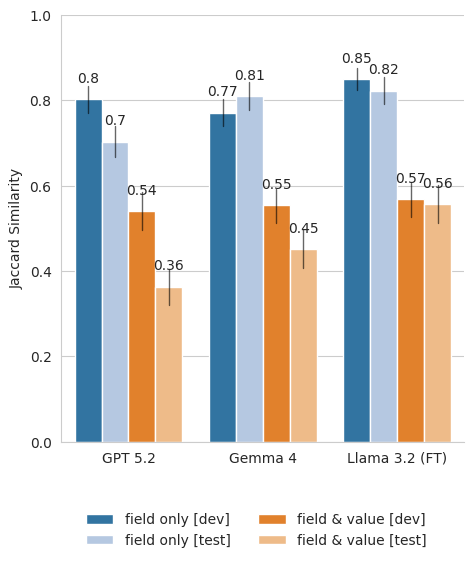

In [21]:
import seaborn as sns

sns.set_style('whitegrid')

fig_df = pd.melt(rev_df, id_vars=['model', 'retrieval', 'filepath.partition'], value_vars=['field_jaccard', 'jaccard'], var_name='metric')
fig_df['level'] = 'field & value'
fig_df['retrieval'] = fig_df['retrieval'].apply(lambda ret: {'medcpt-goat': 'MedCPT (FT)', 'qwen-mongoose': 'Qwen 3'}.get(ret, ret))
fig_df['ret_order'] = fig_df.retrieval.apply(lambda x: [ 'Oracle', 'MedCPT (FT)', 'Qwen 3','Human'].index(x))
fig_df = fig_df[~fig_df.model.isin({'Llama 3.1', 'Mixtral'})]
fig_df.loc[fig_df.metric.str.startswith('field_'), 'level'] = 'field only'
# fig_df['retrieval'] = fig_df['retrieval'] + ' [' + fig_df['filepath.partition'] + ']'
fig_df['partition'] = fig_df['filepath.partition']
fig_df['metric'] =  fig_df['level'] + ' [' + fig_df['partition'] + ']'

fig = sns.catplot(
    fig_df[fig_df.retrieval == 'Qwen 3'].sort_values(['level', 'filepath.partition', 'model'], ascending=[False, True, True]),
    x='model',
    y='value',
    errorbar=('ci', 95),
    hue='metric',
    n_boot=1000,
    err_kws=ERR_KWS,
    palette='tab20',
    kind='bar',
    # col='level'
)
add_bar_labels(fig, fmt=lambda x: round(x, 2), padding=10)
fig.set(ylabel='Jaccard Similarity', xlabel='', ylim=(0,1))
sns.move_legend(
    fig,
    loc="upper left",
    bbox_to_anchor=(0.15, 0),
    ncol=2,
    title=None,
)

fig.set_titles(template="{col_name}")

In [10]:


for _, row in rev_df[rev_df['recall'] == 0].sample(n=100).iterrows():
    print(row['model'])
    _, revision = drop_matched_sections(json.loads(row['claim.flat']), json.loads(row['revised_claim.flat']))
    print(row['claim.flat'])
    print('expected revision')
    print(revision)
    print()
    _, new_revision = drop_matched_sections(json.loads(row['claim.flat']), json.loads(row['parsed'].get('revision')))
    print('found revision')
    print(new_revision)
    print('\n\n\n\n\n')

Gemma 4
{
  "disease": "TFE3-rearranged renal cell carcinoma",
  "evidenceDirection": "DOES_NOT_SUPPORT",
  "evidenceType": "PREDICTIVE",
  "molecularProfile": "VHL Mutation",
  "significance": "resistance",
  "therapies": [
    "Anti-VEGF Monoclonal Antibody"
  ],
  "variantOrigin": "SOMATIC"
}
expected revision
{'disease': 'Renal Cell Carcinoma', 'significance': 'sensitivity/response'}

found revision
{'disease': 'Clear Cell Renal Cell Carcinoma'}






Gemma 4
{
  "disease": "Renal Cell Carcinoma",
  "evidenceDirection": "DOES_NOT_SUPPORT",
  "evidenceType": "PREDICTIVE",
  "molecularProfile": "VHL Mutation",
  "significance": "resistance",
  "therapies": [
    "Anti-VEGF Monoclonal Antibody"
  ],
  "variantOrigin": "SOMATIC"
}
expected revision
{'significance': 'sensitivity/response'}

found revision
{'evidenceDirection': 'SUPPORTS', 'significance': 'no effect'}






Llama 3.2 (FT)
{
  "disease": "brain disease",
  "evidenceDirection": "SUPPORTS",
  "evidenceType": "PROGNOSTIC",
 

In [11]:
for _, row in rev_df[(rev_df['recall'] == 1) & (rev_df['precision'] == 1)].sample(n=100).iterrows():
    print(row['model'])
    _, revision = drop_matched_sections(json.loads(row['claim.flat']), json.loads(row['revised_claim.flat']))
    print(row['claim.flat'])
    print('expected revision')
    print(revision)
    print()
    _, new_revision = drop_matched_sections(json.loads(row['claim.flat']), json.loads(row['parsed'].get('revision')))
    print('found revision')
    print(new_revision)
    print('\n\n\n\n\n')

Gemma 4
{
  "disease": "Pancreatic Cancer",
  "evidenceDirection": "DOES_NOT_SUPPORT",
  "evidenceType": "PREDICTIVE",
  "molecularProfile": "BRCA2 Mutation",
  "significance": "sensitivity/response",
  "therapies": [
    "Platinum Compound"
  ],
  "variantOrigin": "RARE_GERMLINE"
}
expected revision
{'evidenceDirection': 'SUPPORTS'}

found revision
{'evidenceDirection': 'SUPPORTS'}






Llama 3.2 (FT)
{
  "disease": "adenocarcinoma",
  "evidenceDirection": "SUPPORTS",
  "evidenceType": "PREDICTIVE",
  "molecularProfile": "BRAF V656I",
  "significance": "sensitivity/response",
  "therapies": [
    "Dabrafenib",
    "Trametinib"
  ],
  "therapyInteractionType": "COMBINATION",
  "variantOrigin": "SOMATIC"
}
expected revision
{'disease': 'Lung Non-small Cell Carcinoma', 'molecularProfile': 'BRAF V600E'}

found revision
{'disease': 'Lung Non-small Cell Carcinoma', 'molecularProfile': 'BRAF V600E'}






Gemma 4
{
  "disease": "cervical endometrioid adenocarcinoma",
  "evidenceDirection": 